### Question 3
Does attention extend beyond the pair? After A links negatively to B, do other communities start linking to B more often? Are those links disproportionately negative, or does B simply receive more attention of every kind? We could then examine triangles: whether those third communities were already connected to A or B. This brings together Anaki’s network idea and Hippolyte’s bridge idea, and provides a visually strong final chapter.


### Exploring signed temporal triangles

Beyond measuring changes in attention toward a targeted subreddit, we investigate whether the pre-existing relationships between communities are associated with subsequent negative interactions.

More specifically, we test the following hypothesis:

**Are communities positively connected to an attacker A more likely to link negatively to the target B after A publishes a negative link toward B?**

We focus on three communities:
- **A:** the subreddit initiating a negative link toward B.
- **B:** the subreddit receiving the negative link.
- **C:** a third-party subreddit that subsequently links to B.

This analysis aims to explore whether negative interactions involve communities that were already connected to the attacker. It does not establish that the initial negative link caused subsequent interactions.

In [70]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

pd.set_option("display.max_columns", 20)

sns.set_theme(style="whitegrid", context="notebook")

In [71]:
data_dir = Path("data/raw")
columns = ["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "POST_ID", "TIMESTAMP", "LINK_SENTIMENT"]
files = {"body": data_dir / "soc-redditHyperlinks-body.tsv",
         "title": data_dir / "soc-redditHyperlinks-title.tsv"}
for path in files.values():
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. See dataset_information.md for download instructions.")

parts = []
for location, path in files.items():
    part = pd.read_csv(path, sep="	", usecols=columns,
                       dtype={"SOURCE_SUBREDDIT": "string", "TARGET_SUBREDDIT": "string",
                              "POST_ID": "string", "TIMESTAMP": "string", "LINK_SENTIMENT": "int8"})
    part["LOCATION"] = location
    parts.append(part)
links = pd.concat(parts, ignore_index=True)
print(f"Loaded {len(links):,} links: {len(parts[0]):,} body and {len(parts[1]):,} title")

print("Missing values by column:")
display(links.isna().sum().to_frame("missing"))
print("Sentiment labels:", links["LINK_SENTIMENT"].value_counts().to_dict())
print("Duplicate rows:", links.duplicated().sum())
print("Self-links:", (links["SOURCE_SUBREDDIT"] == links["TARGET_SUBREDDIT"]).sum())

assert not links[columns].isna().any().any()
assert set(links["LINK_SENTIMENT"]) == {-1, 1}
assert not links.duplicated().any()


# Parse dates before ordering links within each pair.
links["time"] = pd.to_datetime(links.pop("TIMESTAMP"), errors="coerce")
assert links["time"].notna().all()
links = links.loc[links["SOURCE_SUBREDDIT"] != links["TARGET_SUBREDDIT"]].copy()
links = links.sort_values(["time", "POST_ID", "LOCATION"]).reset_index(drop=True)

# One unordered key identifies a relationship; source and target preserve its direction.
links["pair_a"] = np.minimum(links["SOURCE_SUBREDDIT"], links["TARGET_SUBREDDIT"]).astype("string")
links["pair_b"] = np.maximum(links["SOURCE_SUBREDDIT"], links["TARGET_SUBREDDIT"]).astype("string")
links["LOCATION"] = links["LOCATION"].astype("category")
assert not any(dtype == "object" for dtype in links.dtypes)
links.info()
print(f"{len(links):,} usable links in {links.groupby(['pair_a', 'pair_b']).ngroups:,} pairs")
print(f"Observed period: {links['time'].min()} to {links['time'].max()}")

Loaded 858,488 links: 286,561 body and 571,927 title
Missing values by column:


,missing
SOURCE_SUBREDDIT,0
TARGET_SUBREDDIT,0
POST_ID,0
TIMESTAMP,0
LINK_SENTIMENT,0
LOCATION,0


Sentiment labels: {1: 776278, -1: 82210}
Duplicate rows: 0
Self-links: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 858488 entries, 0 to 858487
Data columns (total 8 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   SOURCE_SUBREDDIT  858488 non-null  string        
 1   TARGET_SUBREDDIT  858488 non-null  string        
 2   POST_ID           858488 non-null  string        
 3   LINK_SENTIMENT    858488 non-null  int8          
 4   LOCATION          858488 non-null  category      
 5   time              858488 non-null  datetime64[ns]
 6   pair_a            858488 non-null  string        
 7   pair_b            858488 non-null  string        
dtypes: category(1), datetime64[ns](1), int8(1), string(5)
memory usage: 40.9 MB
858,488 usable links in 309,667 pairs
Observed period: 2013-12-31 16:20:20 to 2017-04-30 16:58:21


In [72]:
links

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,LINK_SENTIMENT,LOCATION,time,pair_a,pair_b
0,agitation,changemyview,1u5cj7s,1,title,2013-12-31 16:20:20,agitation,changemyview
1,rddtgaming,rddtrust,1u4pzzs,1,title,2013-12-31 16:39:18,rddtgaming,rddtrust
2,leagueoflegends,teamredditteams,1u4nrps,1,body,2013-12-31 16:39:58,leagueoflegends,teamredditteams
3,examplesofevil,pics,1u5lhas,1,title,2013-12-31 16:40:29,examplesofevil,pics
4,nfl,cfb,1u4sjvs,1,body,2013-12-31 17:37:55,cfb,nfl
...,...,...,...,...,...,...,...,...
858483,brasilonreddit,bad_cop_no_donut,68ifuvs,1,title,2017-04-30 16:47:50,bad_cop_no_donut,brasilonreddit
858484,brasilonreddit,roadcam,68ipe8s,1,title,2017-04-30 16:47:50,brasilonreddit,roadcam
858485,mgtow,dataisbeautiful,68ipeos,1,body,2017-04-30 16:52:59,dataisbeautiful,mgtow
858486,mmorpg,blackdesertonline,68ip5os,1,body,2017-04-30 16:54:08,blackdesertonline,mmorpg


In [73]:
# Negative links
negative_links = links[links["LINK_SENTIMENT"] == -1].copy()

# Events from 2015 onward
#negative_links = negative_links[
#    negative_links["time"] >= "2015-01-01"
#]


### Event selection

We define an event as the **first observed negative hyperlink received by a target subreddit B** in the available dataset, so the first attack available in the dataset.

To identify these events, we first consider the complete observed history, then retain only events occurring from January 1, 2015 onward.

This allows us to use earlier observations, particularly those from 2014, to examine pre-existing relationships between communities.

We also exclude events without a complete 30-day observation period afterward.

Each event is represented by:
- **A:** the source of the negative hyperlink.
- **B:** the target of the negative hyperlink.
- **t0:** the timestamp of the event.

Importantly, the first *observed* negative link is not necessarily the first negative interaction in the history of these communities.

In [74]:
# First observed negative link received by each B
events = (
    negative_links
    .sort_values("time")
    .drop_duplicates(subset="TARGET_SUBREDDIT")
    .copy()
)

events = events.rename(columns={
    "SOURCE_SUBREDDIT": "A",
    "TARGET_SUBREDDIT": "B",
    "time": "t0"
})

events = events[["A", "B", "t0"]]

# Keep events from 2015 with complete 30-day follow-up
events = events[
    (events["t0"] >= "2015-01-01") &
    (events["t0"] + pd.Timedelta(days=30) <= links["time"].max())
].reset_index(drop=True)

events.head()

,A,B,t0
0,shitgonewildsays,analgw,2015-01-01 00:45:17
1,bad_religion,sikh,2015-01-02 01:49:20
2,writingprompts,medievalhistory,2015-01-02 09:15:16
3,globaloffensive,recruitcs,2015-01-02 20:00:16
4,subredditdrama,rcigarsbattlezone,2015-01-02 21:03:42


In [75]:
links_by_target = {
    target: group
    for target, group in links.groupby("TARGET_SUBREDDIT")
}

links_by_source = {
    source: group
    for source, group in links.groupby("SOURCE_SUBREDDIT")
}

### Detecting signed temporal triangles

For each negative event A → B at time t0, we investigate whether third-party communities C were positively connected to A before the event and subsequently linked negatively to B.

We use two event-centered observation windows:

- **90 days before t0:** identify positive hyperlinks between A and C, regardless of direction (A → C or C → A).
- **30 days after t0:** observe hyperlinks from C to B and their sentiment.

A triangle matching our hypothesis consists of:

1. At least one positive hyperlink between A and C during the 90 days before t0.
2. A negative hyperlink A → B at t0.
3. At least one negative hyperlink C → B within the following 30 days.

We additionally record whether C had already linked to B during the preceding 90 days. This helps distinguish previously observed C–B interactions from interactions not observed in the recent history.

For this preliminary analysis, a single positive hyperlink is sufficient to classify A and C as positively connected. This does not necessarily imply that the two communities are allies.

The 90-day and 30-day windows are methodological choices that can be tested with alternative durations in the final analysis.

In [76]:
def find_triangles_fast(A, B, t0, window=30, lookback=90):

    start = t0 - pd.Timedelta(days=lookback)

    # 1. Find C → B links after the attack
    target_links = links_by_target.get(B)

    if target_links is None:
        return None

    after = target_links[
        (target_links["time"] > t0) &
        (target_links["time"] <= t0 + pd.Timedelta(days=window)) &
        (target_links["SOURCE_SUBREDDIT"] != A) &
        (target_links["SOURCE_SUBREDDIT"] != B)
    ].copy()

    if after.empty:
        return None

    # 2. Find positive connections A ↔ C before the attack
    outgoing = links_by_source.get(A)
    incoming = links_by_target.get(A)

    positive_neighbors = set()

    if outgoing is not None:
        positive_neighbors.update(
            outgoing.loc[
                (outgoing["time"] >= start) &
                (outgoing["time"] < t0) &
                (outgoing["LINK_SENTIMENT"] == 1),
                "TARGET_SUBREDDIT"
            ]
        )

    if incoming is not None:
        positive_neighbors.update(
            incoming.loc[
                (incoming["time"] >= start) &
                (incoming["time"] < t0) &
                (incoming["LINK_SENTIMENT"] == 1),
                "SOURCE_SUBREDDIT"
            ]
        )

    # 3. Find previous connections C → B
    previous_CB = target_links[
        (target_links["time"] >= start) &
        (target_links["time"] < t0)
    ]

    previous_sources = set(
        previous_CB["SOURCE_SUBREDDIT"]
    )

    # 4. Add information to the dataframe
    after["A"] = A
    after["B"] = B
    after["C"] = after["SOURCE_SUBREDDIT"]
    after["t0"] = t0

    after["positive_AC"] = (
        after["C"].isin(positive_neighbors)
    )

    after["previous_CB"] = (
        after["C"].isin(previous_sources)
    )

    after["negative_CB"] = (
        after["LINK_SENTIMENT"] == -1
    )

    return after

In [77]:
all_results = []

for event in events.itertuples(index=False):

    result = find_triangles_fast(
        A=event.A,
        B=event.B,
        t0=event.t0,
        window=30,
        lookback=90
    )

    if result is not None:
        all_results.append(result)

if all_results:
    all_third_party_links = pd.concat(
        all_results,
        ignore_index=True
    )
else:
    all_third_party_links = pd.DataFrame()

display(all_third_party_links.head())

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,LINK_SENTIMENT,LOCATION,time,pair_a,pair_b,A,B,C,t0,positive_AC,previous_CB,negative_CB
0,deadmalls,urbanexploration,2vgc54s,1,title,2015-01-06 08:45:35,deadmalls,urbanexploration,saltlakecity,urbanexploration,deadmalls,2015-01-03 18:27:09,False,False,False
1,writingprompts,urbanexploration,2ryewds,1,body,2015-01-10 03:20:25,urbanexploration,writingprompts,saltlakecity,urbanexploration,writingprompts,2015-01-03 18:27:09,False,False,False
2,hiphopheads,deathgrips,2rdwpns,1,title,2015-01-05 00:48:07,deathgrips,hiphopheads,bestof,deathgrips,hiphopheads,2015-01-04 22:17:19,True,False,False
3,outoftheloop,deathgrips,2rf5u6s,1,body,2015-01-05 09:57:18,deathgrips,outoftheloop,bestof,deathgrips,outoftheloop,2015-01-04 22:17:19,True,False,False
4,pixelsorting,deathgrips,2scdw7s,1,title,2015-01-15 12:15:54,deathgrips,pixelsorting,bestof,deathgrips,pixelsorting,2015-01-04 22:17:19,False,False,False


### Counting negative temporal triangles

After applying the detection procedure to all selected events, we retain the observations satisfying both conditions:

- C had a positive connection with A before the negative event.
- C published a negative hyperlink toward B after the event.

We then count distinct combinations of (A, B, t0, C).

This avoids counting multiple negative hyperlinks from the same community C toward B as separate triangles for the same event.

In [78]:
# Triangles where C had a positive tie with A
positive_triangles = all_third_party_links[
    all_third_party_links["positive_AC"]
].copy()

# Triangles where C negatively links to B after A's attack
negative_triangles = positive_triangles[
    positive_triangles["negative_CB"]
].copy()

# Count distinct triangles
n_triangles = (
    negative_triangles[["A", "B", "t0", "C"]]
    .drop_duplicates()
    .shape[0]
)

print("Number of negative triangles:", n_triangles)

Number of negative triangles: 253


In [92]:
summary = all_third_party_links.groupby("positive_AC").agg(
    n_links=("negative_CB", "size"),
    negative_share=("negative_CB", "mean")
)

display(summary)
summary.index

,n_links,negative_share
positive_AC,,
False,5481,0.091772
True,1786,0.153975


Index([False, True], dtype='bool', name='positive_AC')

Text(0, 0.5, 'Share of negative C → B links')

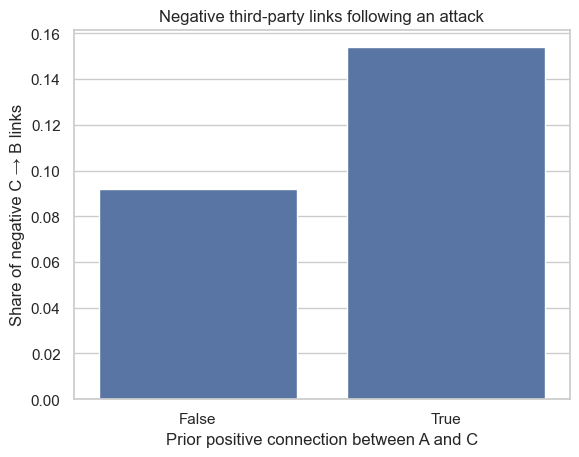

In [94]:
ax = sns.barplot(x=summary.index, y="negative_share", data=summary)
ax.set_title(
    "Negative third-party links following an attack"
)
ax.set_xlabel("Prior positive connection between A and C")
ax.set_ylabel("Share of negative C → B links")